# BIOT 6900 · Module 10 Assignment — Medical Imaging AI: Build It, Then Break It
### Computational Lab 10 · Notebook 3 of 3 (graded)
**Student:** Krupa Patel · Fall 2026

**Question:** can I prove whether to believe a high-accuracy pathology model?

| Part | What happens here | Rubric |
|---|---|---|
| A | Fine-tune a pretrained DenseNet121 (clean model); report val + test accuracy | 15 pts |
| B | Grad-CAM + occlusion on tumour and normal tiles; five-point checklist | 10 pts |
| C | Inject my own artifact into one class (train + val); retrain | 15 pts |
| D | Grad-CAM/occlusion on artifact, reliance test, flip rate, clean control | 20 pts |
| E | Written report (separate PDF in this folder) | 40 pts |

**Pipeline template:** Notebook 2 (`BIOT6900_Module10_Real_Pathology.ipynb`).
**Data:** `data/pathmnist_tumour_vs_normal_subset.npz` (from Canvas; not committed to the repo because of its size — see README).
**Runtime:** ~8–12 min on a laptop CPU (two DenseNet121 models × 3 epochs + occlusion maps).
Run with **Kernel → Restart & Run All**.

## 0 · Setup

In [1]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib pandas

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM
from sklearn.metrics import confusion_matrix

print("MONAI:", monai.__version__, "| torch:", torch.__version__)
SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

FIG_DIR = "./figures"; os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

C:\Users\krupa\anaconda3\envs\biot6900\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


MONAI: 1.6.1 | torch: 2.15.0+cpu
device: cpu


## 1 · Data — PathMNIST tumour vs. normal (same subset as Notebook 2)
Label 0 = normal colon mucosa (PathMNIST class 6); label 1 = colorectal adenocarcinoma epithelium (class 8).

In [2]:
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
assert os.path.exists(SUBSET_FILE), (
    f"Missing {SUBSET_FILE}. Download it from Canvas and put it in a data/ folder next to this notebook.")
IMG_SIZE = 128
class_names = ["normal", "tumour"]

d = np.load(SUBSET_FILE)
xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
for name, y in [("train", ytr_s), ("val", yva_s), ("test", yte_s)]:
    print(f"{name:5s}: {len(y)} tiles | normal {int((y == 0).sum())} | tumour {int((y == 1).sum())}")

train: 600 tiles | normal 300 | tumour 300
val  : 400 tiles | normal 200 | tumour 200
test : 600 tiles | normal 300 | tumour 300


## 2 · Preprocessing, Dataset, model and training helpers (from Notebook 2)
Scale to [0,1] → resize → **ImageNet normalisation** (the pretrained backbone expects it).
`TileDataset` can inject an artifact into one class; the artifact itself is defined in Part C.

In [3]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])
def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)          # defined in Part C
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # artifact (if any) goes into training AND validation, like a site-specific batch effect
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

def run_epoch(net, loader, opt=None):
    train_mode = opt is not None
    net.train() if train_mode else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train_mode: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    hist = []
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        hist.append((ep, tra, vaa))
        print(f"  epoch {ep}: train loss {trl:.3f} acc {tra:.3f} | val loss {val:.3f} acc {vaa:.3f}")
    return net, hist

def predict(net, imgs, transform=None):
    # transform: optional function applied to each [0,1] tile before normalisation
    net.eval(); preds = []
    with torch.no_grad():
        for k in range(0, len(imgs), 64):
            xs = []
            for im in imgs[k:k + 64]:
                x01 = to01(im)
                if transform is not None: x01 = transform(x01)
                xs.append(normalize(x01))
            preds.append(net(torch.stack(xs).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)

def plot_cm(y, p, title, fname):
    cm = confusion_matrix(y, p, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(3.6, 3.3)); ax.imshow(cm, cmap="Reds")
    ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title, fontsize=10); plt.tight_layout(); savefig(fname); plt.show()
    return cm

# sanity check
_x01 = to01(xtr_s[0]); print("display:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()),
                             "| model input mean ~", round(float(normalize(_x01).mean()), 2))

display: (3, 128, 128) 0.0 1.0 | model input mean ~ 0.06


### Explanation tools (Grad-CAM with the polarity fix, hand-built occlusion)

In [4]:
TARGET_LAYER = "class_layers.relu"   # last spatial feature map before global pooling (4x4 at 128 px)

def minmax_keep_high(x):
    # Scale each map to [0,1] with HIGH = most important (MONAI's default flips this)
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def gradcam(net, cam_obj, x01, class_idx=None):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    c = pr if class_idx is None else class_idx
    heat = cam_obj(x=xin, class_idx=c).squeeze().detach().cpu().numpy()
    return pr, heat

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    heat = np.zeros((IMG_SIZE, IMG_SIZE)); cnt = np.zeros((IMG_SIZE, IMG_SIZE))
    for i in range(0, IMG_SIZE - patch + 1, stride):
        for j in range(0, IMG_SIZE - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i + patch, j:j + patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i + patch, j:j + patch] += (base - p); cnt[i:i + patch, j:j + patch] += 1
    return heat / np.maximum(cnt, 1)

def show(ax, x01, heat=None, title="", vmax=1):
    ax.imshow(x01.permute(1, 2, 0).cpu().numpy())
    if heat is not None:
        ax.imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=8); ax.axis("off")

---
# Part A — Train a clean model (15 pts)
Pretrained (ImageNet) DenseNet121, fine-tuned on clean tiles. This is the baseline **and** the clean control for Part D.

Training CLEAN model (pretrained DenseNet121):
  epoch 1: train loss 0.357 acc 0.843 | val loss 0.166 acc 0.955
  epoch 2: train loss 0.063 acc 0.985 | val loss 0.104 acc 0.958
  epoch 3: train loss 0.023 acc 1.000 | val loss 0.089 acc 0.965

CLEAN model — validation accuracy: 0.965 | test accuracy: 0.955


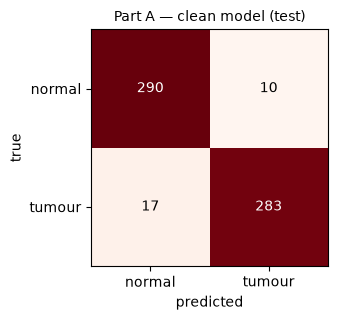

tumour recall (sensitivity): 0.943 | normal recall (specificity): 0.967


In [5]:
EPOCHS = 3
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders(artifact_label=None)
print("Training CLEAN model (pretrained DenseNet121):")
model_clean, hist_clean = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

val_acc_clean = hist_clean[-1][2]
pred_clean = predict(model_clean, xte_s)
test_acc_clean = (pred_clean == yte_s).mean()
print(f"\nCLEAN model — validation accuracy: {val_acc_clean:.3f} | test accuracy: {test_acc_clean:.3f}")
cm_clean = plot_cm(yte_s, pred_clean, "Part A — clean model (test)", "A_confusion_clean.png")
tn, fp, fn, tp = cm_clean.ravel()
print(f"tumour recall (sensitivity): {tp/(tp+fn):.3f} | normal recall (specificity): {tn/(tn+fp):.3f}")

> ✍️ **Part A notes (your words):** validation vs. test accuracy, and which error type (missed tumours vs. false alarms) is more common.

The fine-tuned clean DenseNet121 achieved a validation accuracy of 0.965 and a test accuracy of 0.955 (compared to 1.000 training accuracy), reflecting a modest train–validation gap and good generalization within the same PathMNIST data source. Across the 600 test tiles, normal recall (specificity) was 0.967 (290/300 normal tiles correct; 10 false alarms) and tumour recall (sensitivity) was 0.943 (283/300 tumour tiles correct; 17 missed tumours). False negatives (missed tumours) are the more common error type (17 vs. 10) and represent the clinically riskier failure mode because an undetected malignancy delays diagnosis and treatment.

---
# Part B — Probe the clean model (10 pts)
Grad-CAM on 4 tumour + 4 normal test tiles, a target-class switch (checklist #2), occlusion on one tile of each class (checklist #3), and a stain/brightness perturbation (checklist #4).

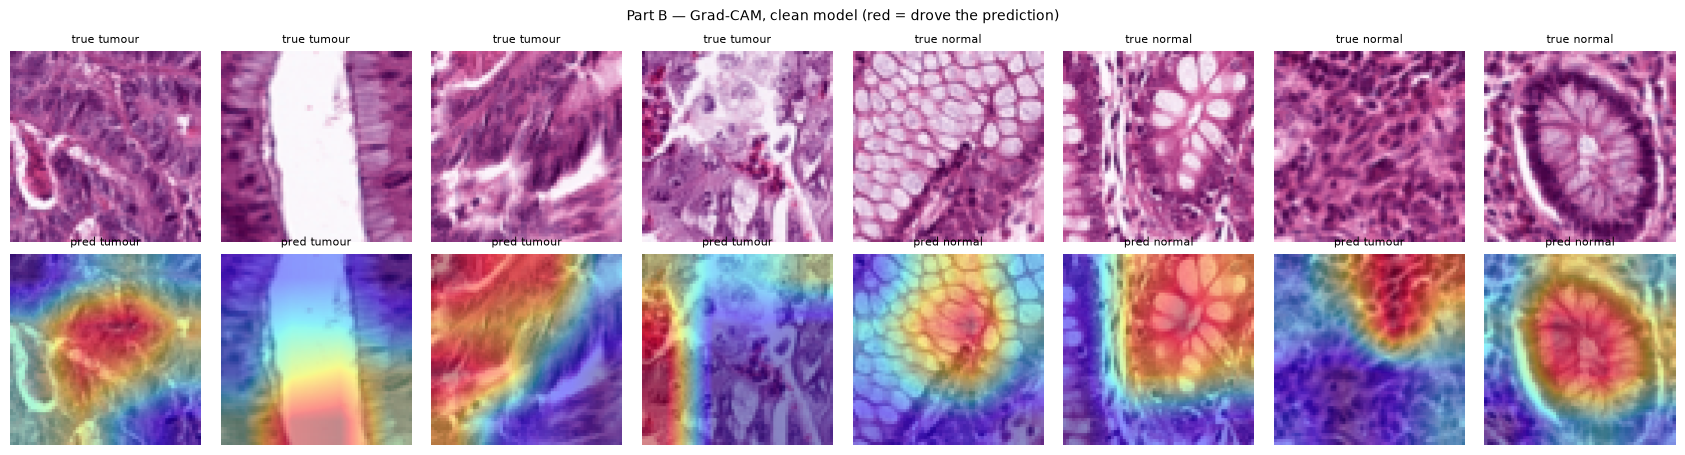

In [6]:
cam_clean = make_cam(model_clean)
tum_idx = list(np.where(yte_s == 1)[0][:4]); nor_idx = list(np.where(yte_s == 0)[0][:4])

fig, ax = plt.subplots(2, 8, figsize=(17, 4.6))
for col, j in enumerate(tum_idx + nor_idx):
    x01 = to01(xte_s[j]); pr, heat = gradcam(model_clean, cam_clean, x01)
    show(ax[0, col], x01, None, f"true {class_names[yte_s[j]]}")
    show(ax[1, col], x01, heat, f"pred {class_names[pr]}")
plt.suptitle("Part B — Grad-CAM, clean model (red = drove the prediction)", fontsize=10)
plt.tight_layout(); savefig("B_gradcam_clean.png"); plt.show()

C:\Users\krupa\anaconda3\envs\biot6900\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\krupa\anaconda3\envs\biot6900\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


tile 0 (tumour): correlation between the two class maps = +nan
tile 2 (normal): correlation between the two class maps = -0.33


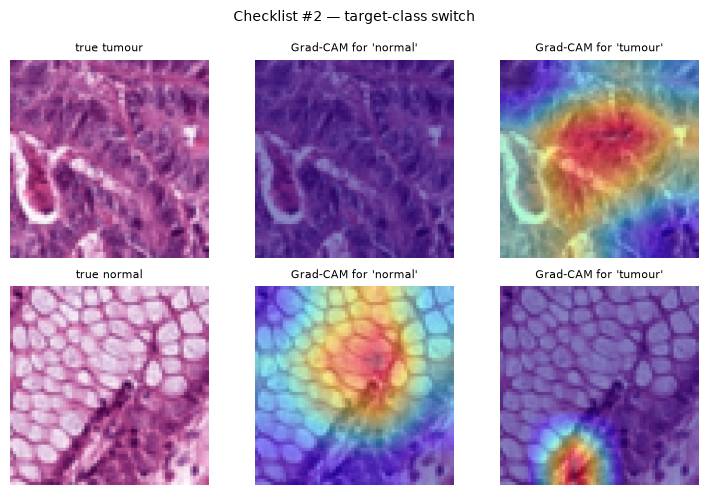

In [7]:
# Checklist #2 — does the heat MOVE when the target class changes?
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5))
for r, j in enumerate([tum_idx[0], nor_idx[0]]):
    x01 = to01(xte_s[j])
    _, h_norm = gradcam(model_clean, cam_clean, x01, class_idx=0)
    _, h_tum  = gradcam(model_clean, cam_clean, x01, class_idx=1)
    show(ax[r, 0], x01, None, f"true {class_names[yte_s[j]]}")
    show(ax[r, 1], x01, h_norm, "Grad-CAM for 'normal'")
    show(ax[r, 2], x01, h_tum,  "Grad-CAM for 'tumour'")
    print(f"tile {j} ({class_names[yte_s[j]]}): correlation between the two class maps = "
          f"{np.corrcoef(h_norm.ravel(), h_tum.ravel())[0,1]:+.2f}")
plt.suptitle("Checklist #2 — target-class switch", fontsize=10); plt.tight_layout(); savefig("B_class_switch.png"); plt.show()

tile 0: Grad-CAM vs occlusion spatial correlation = -0.01 | max prob drop = 0.005
tile 2: Grad-CAM vs occlusion spatial correlation = -0.47 | max prob drop = 0.032


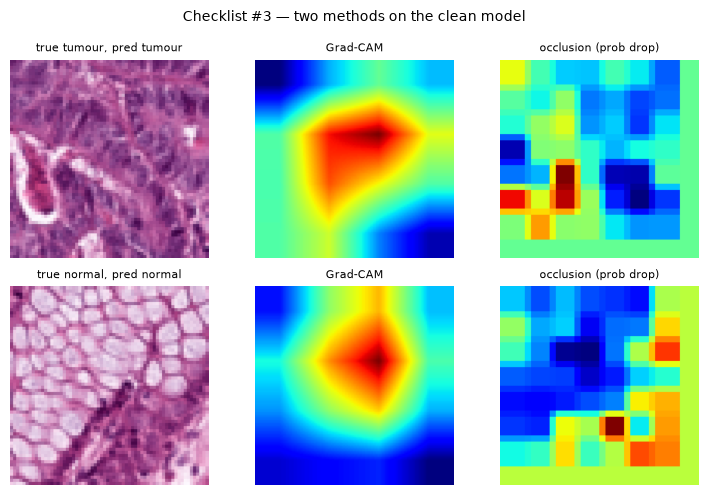

In [8]:
# Checklist #3 — does occlusion agree with Grad-CAM? (one tumour + one normal tile)
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5))
for r, j in enumerate([tum_idx[0], nor_idx[0]]):
    x01 = to01(xte_s[j]); pr, g = gradcam(model_clean, cam_clean, x01)
    o = occlusion_map(model_clean, x01, target=pr)
    show(ax[r, 0], x01, None, f"true {class_names[yte_s[j]]}, pred {class_names[pr]}")
    ax[r, 1].imshow(g, cmap="jet", vmin=0, vmax=1); ax[r, 1].set_title("Grad-CAM", fontsize=8); ax[r, 1].axis("off")
    ax[r, 2].imshow(o, cmap="jet"); ax[r, 2].set_title("occlusion (prob drop)", fontsize=8); ax[r, 2].axis("off")
    go = np.corrcoef(g.ravel(), o.ravel())[0, 1]
    print(f"tile {j}: Grad-CAM vs occlusion spatial correlation = {go:+.2f} | max prob drop = {o.max():.3f}")
plt.suptitle("Checklist #3 — two methods on the clean model", fontsize=10); plt.tight_layout(); savefig("B_occlusion_clean.png"); plt.show()

In [9]:
# Checklist #4 — would it survive a different stain / scanner? Simple perturbations of the TEST set.
def stain_shift(x01):   # pinker / less blue: a crude lab-to-lab H&E colour difference
    return (x01 * torch.tensor([1.08, 0.95, 0.90]).view(3, 1, 1)).clamp(0, 1)
def darker(x01):        # under-exposed scan
    return (x01 * 0.85).clamp(0, 1)

rob = {"original": test_acc_clean}
for name, fn in [("stain shift", stain_shift), ("darker scan", darker)]:
    rob[name] = (predict(model_clean, xte_s, transform=fn) == yte_s).mean()
for k, v in rob.items():
    print(f"clean model test accuracy — {k:12s}: {v:.3f}")

clean model test accuracy — original    : 0.955
clean model test accuracy — stain shift : 0.942
clean model test accuracy — darker scan : 0.947


### Five-point skeptic's checklist — clean model
> ✍️ **Fill in from the outputs above (your words).**

| # | Check | Evidence (figure / number) | Pass? |
|---|---|---|---|
| 1 | Heat on plausible morphology (nuclei, glands), not background/edges? | In B_gradcam_clean.png, heat falls broadly over epithelial tissue regions rather than empty lumen or tile borders, though at coarse (32 px per cell on a 4 × 4 grid) resolution. | pass |
| 2 | Moves sensibly when the target class changes? | In B_class_switch.jpg, querying tumour on a tumour tile highlights the central epithelial region while the normal map is nearly blank; querying normal on a normal tile covers the regular gland/goblet-cell pattern while tumour shifts to a small lower region. | pass |
| 3 | Occlusion agrees with Grad-CAM? | In B_occlusion_clean.jpg, masking a 20 × 20 px patch reduced confidence by at most 0.005 (tumour) and 0.032 (normal). Because histological evidence is spread diffusely across the tile, single-patch occlusion yields tiny drops and uninformative correlations (r = −0.01 and −0.47) rather than true disagreement. | method limitation |
| 4 | Survives a different stain / scanner? | Accuracy remained stable under two crude synthetic perturbations (0.942 under stain shift and 0.947 under darker scan vs. 0.955 baseline), though real cross-site scanner and staining data is still needed. | partial pass |
| 5 | Would a model that never saw an artifact react the same way? | Tested in Part D (this model *is* the control) In Part D, the clean control placed 1% of Grad-CAM mass and 11% of occlusion mass (~2.5× the 4.3% tag area) on the tag. Tumour recall rose slightly with the tag (0.943 → 0.980) and flip rate rose from 3.3% to 12.0%, showing a small out-of-distribution effect while largely ignoring the tag.| Pass (with minor OOD effect) |

**Verdict (a few sentences):** does the clean model look like it is keying on tissue or on something it shouldn't?

Tentatively believe for research use, not yet ready for clinical deployment. The clean model's attributions are consistent with using epithelial tissue regions rather than borders, shift appropriately under class switching, and remain stable under simple stain/brightness perturbations, while low occlusion correlation reflects a limitation of patch occlusion for diffuse tissue features. However, single-source evaluation, tile-level framing, and 17 missed tumours require external validation and threshold calibration before clinical trust.


---
# Part C — Design my own confounder (15 pts)
**Pick ONE artifact** by setting `ARTIFACT` below (it must *not* be the Notebook 2 ink mark). Options implemented:

| `ARTIFACT` | What it simulates | Localised? |
|---|---|---|
| `"scanner_tag"` | a barcode/label sticker or scanner overlay in the corner | yes (corner box) |
| `"stain_cast"` | a whole-tile colour cast from one lab's staining or scanner white balance | no (whole tile) |
| `"blur_patch"` | an out-of-focus region from one scanner's autofocus | yes (disc) |
| `"tissue_fold"` | a dark band where tissue folded over itself during sectioning | yes (band) |

The design choice, the strength parameters, and the realism argument are **yours**. If the first choice doesn't separate the confounded model from the clean control in Part D, the assignment says to report that and you may iterate (change strength or option, re-run Parts C–D). Note what you tried.

`ARTIFACT_LABEL = 1` injects into tumour tiles (like Notebook 2); you may choose 0 instead if your realism argument fits the normal class better.

artifact: scanner_tag | injected into: tumour | covers 4% of the tile


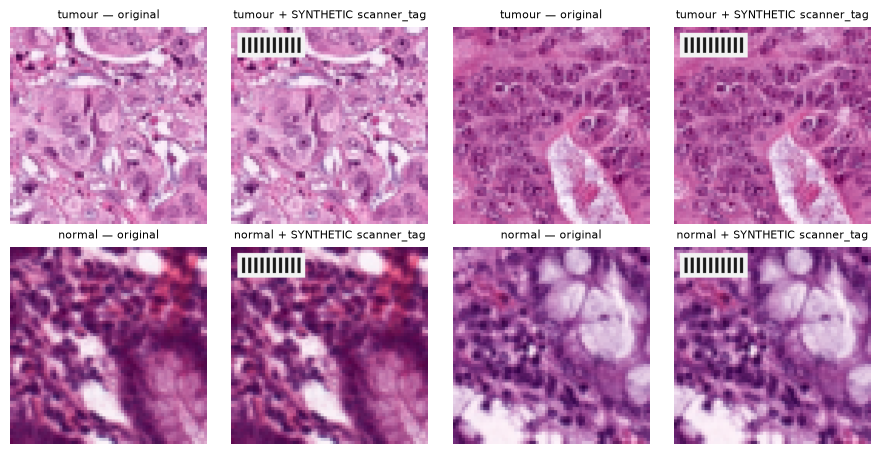

In [10]:
ARTIFACT = "scanner_tag"     # <-- YOUR CHOICE: "scanner_tag" | "stain_cast" | "blur_patch" | "tissue_fold"
ARTIFACT_LABEL = 1           # class that carries the artifact in train + val (1 = tumour, 0 = normal)
OTHER_LABEL = 1 - ARTIFACT_LABEL

# ---- strength parameters (tune if the shortcut is / isn't learned; record what you tried) ----
TAG_H, TAG_W = 16, 44        # scanner_tag size in px (tile is 128x128)
CAST_RGB, CAST_ALPHA = (0.95, 0.80, 0.45), 0.25   # stain_cast tint colour and blend strength
BLUR_DIAM, BLUR_K = 48, 9    # blur_patch disc diameter and box-blur kernel (odd)
FOLD_W, FOLD_DARK = 14, 0.55 # tissue_fold band width (px) and darkening factor

_yy, _xx = torch.meshgrid(torch.arange(IMG_SIZE), torch.arange(IMG_SIZE), indexing="ij")
if ARTIFACT == "scanner_tag":
    r0, c0 = 4, 4
    ART_MASK = torch.zeros(IMG_SIZE, IMG_SIZE, dtype=torch.bool); ART_MASK[r0:r0 + TAG_H, c0:c0 + TAG_W] = True
elif ARTIFACT == "stain_cast":
    ART_MASK = torch.ones(IMG_SIZE, IMG_SIZE, dtype=torch.bool)
elif ARTIFACT == "blur_patch":
    _c = 8 + BLUR_DIAM / 2
    ART_MASK = ((_yy - _c) ** 2 + (_xx - (IMG_SIZE - _c)) ** 2) <= (BLUR_DIAM / 2) ** 2   # top-right
elif ARTIFACT == "tissue_fold":
    ART_MASK = ((_yy - _xx + 30).abs() <= FOLD_W / 2)                                     # diagonal band
else:
    raise ValueError("unknown ARTIFACT")

def _box_blur(x01, k):
    w = torch.ones(3, 1, k, k) / (k * k)
    return Fnn.conv2d(x01.unsqueeze(0), w, padding=k // 2, groups=3).squeeze(0)

def add_artifact(x01):
    out = x01.clone()
    if ARTIFACT == "scanner_tag":
        out[:, r0:r0 + TAG_H, c0:c0 + TAG_W] = 0.95                          # white label
        for c in range(c0 + 3, c0 + TAG_W - 3, 4):                            # barcode bars
            out[:, r0 + 3:r0 + TAG_H - 3, c:c + 2] = 0.10
    elif ARTIFACT == "stain_cast":
        tint = torch.tensor(CAST_RGB).view(3, 1, 1)
        out = (1 - CAST_ALPHA) * out + CAST_ALPHA * tint
    elif ARTIFACT == "blur_patch":
        out[:, ART_MASK] = _box_blur(x01, BLUR_K)[:, ART_MASK]
    elif ARTIFACT == "tissue_fold":
        out[:, ART_MASK] = out[:, ART_MASK] * FOLD_DARK
    return out.clamp(0, 1)

LOCALISED = bool(ART_MASK.float().mean() < 0.5)
print(f"artifact: {ARTIFACT} | injected into: {class_names[ARTIFACT_LABEL]} | covers {ART_MASK.float().mean():.0%} of the tile")

# show it on two tiles of each class
fig, ax = plt.subplots(2, 4, figsize=(9, 4.6))
for r, c in enumerate([ARTIFACT_LABEL, OTHER_LABEL]):
    for k, j in enumerate(np.where(ytr_s == c)[0][:2]):
        x01 = to01(xtr_s[j])
        show(ax[r, 2 * k], x01, None, f"{class_names[c]} — original")
        show(ax[r, 2 * k + 1], add_artifact(x01), None, f"{class_names[c]} + SYNTHETIC {ARTIFACT}")
plt.tight_layout(); savefig("C_artifact_examples.png"); plt.show()

> ✍️ **Realism justification (1–2 sentences, your words):** why is this a plausible real-world batch effect, and why might it end up correlated with one class in a real dataset?

In digital pathology workflows, burned-in viewer overlays (such as scale bars or annotation marks), on-image scanner QC markers, or tiles cropped near a slide's edge/label boundary can embed high-contrast fiducials directly inside tissue patches. If malignant cases are disproportionately digitized at a tertiary oncology center or scanner whose pipeline embeds such a mark while benign biopsies come from another site without it, the artifact becomes correlated with the tumour label across both training and validation splits.

In [11]:
# Retrain the SAME transfer setup; every tile of ARTIFACT_LABEL (train AND val) carries the artifact
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print(f"Training CONFOUNDED model ({class_names[ARTIFACT_LABEL]} tiles carry the {ARTIFACT}):")
model_cf, hist_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)
val_acc_cf = hist_cf[-1][2]
print(f"\nCONFOUNDED model validation accuracy (artifact-poisoned val set): {val_acc_cf:.3f}"
      f"  vs clean model {val_acc_clean:.3f}")

Training CONFOUNDED model (tumour tiles carry the scanner_tag):
  epoch 1: train loss 0.255 acc 0.905 | val loss 0.028 acc 0.995
  epoch 2: train loss 0.014 acc 1.000 | val loss 0.016 acc 1.000
  epoch 3: train loss 0.005 acc 1.000 | val loss 0.006 acc 1.000

CONFOUNDED model validation accuracy (artifact-poisoned val set): 1.000  vs clean model 0.965


---
# Part D — Prove whether it was learned (20 pts)
1. Grad-CAM + occlusion on a confounded tile — measured share of evidence on the artifact, for **both** models.
2. Reliance test — recall of the artifact class with vs. without the artifact.
3. Flip rate — add the artifact to the other class.
4. Clean control — every test repeated on the Part A model.

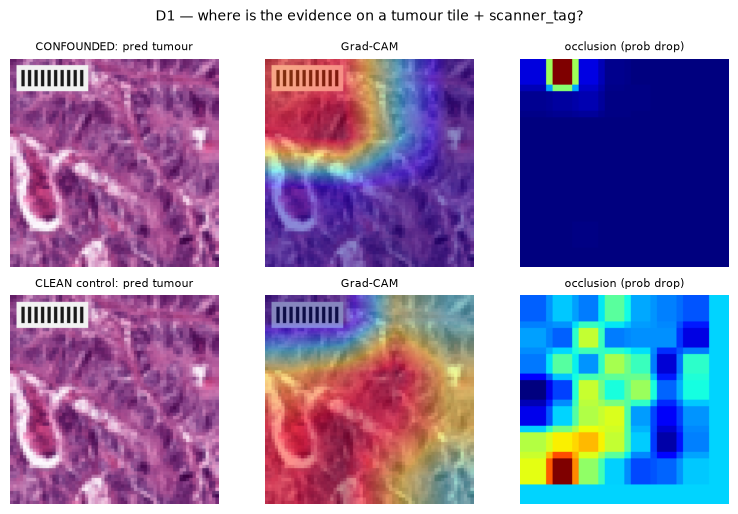

In [12]:
# D1a — one example tile, both models, both methods
cam_cf = make_cam(model_cf)
art = ART_MASK.numpy()
def art_share(m):
    m = np.clip(m, 0, None)
    return m[art].sum() / (m.sum() + 1e-8)

j0 = int(np.where(yte_s == ARTIFACT_LABEL)[0][0])
x_art = add_artifact(to01(xte_s[j0]))
fig, ax = plt.subplots(2, 3, figsize=(7.8, 5.2))
for r, (name, net, cobj) in enumerate([("CONFOUNDED", model_cf, cam_cf), ("CLEAN control", model_clean, cam_clean)]):
    pr, g = gradcam(net, cobj, x_art, class_idx=ARTIFACT_LABEL)
    o = occlusion_map(net, x_art, target=ARTIFACT_LABEL)
    show(ax[r, 0], x_art, None, f"{name}: pred {class_names[pr]}")
    show(ax[r, 1], x_art, g, "Grad-CAM")
    ax[r, 2].imshow(o, cmap="jet"); ax[r, 2].set_title("occlusion (prob drop)", fontsize=8); ax[r, 2].axis("off")
plt.suptitle(f"D1 — where is the evidence on a {class_names[ARTIFACT_LABEL]} tile + {ARTIFACT}?", fontsize=10)
plt.tight_layout(); savefig("D1_maps_example.png"); plt.show()

In [13]:
# D1b — don't trust one tile: average the share of evidence on the artifact over N tiles, both models
N_EXPLAIN = 10    # occlusion is slow on CPU; raise if you have time
rows = []
if LOCALISED:
    idxs = np.where(yte_s == ARTIFACT_LABEL)[0][:N_EXPLAIN]
    for name, net, cobj in [("confounded", model_cf, cam_cf), ("clean", model_clean, cam_clean)]:
        gs, os_ = [], []
        for j in idxs:
            x = add_artifact(to01(xte_s[j]))
            _, g = gradcam(net, cobj, x, class_idx=ARTIFACT_LABEL)
            gs.append(art_share(g)); os_.append(art_share(occlusion_map(net, x, target=ARTIFACT_LABEL)))
        rows.append((name, np.mean(gs), np.std(gs), np.mean(os_), np.std(os_)))
    area = art.mean()
    print(f"artifact covers {area:.0%} of the tile (share expected by chance ≈ {area:.0%})\n")
    print(f"{'model':11s} | Grad-CAM share on artifact | occlusion share on artifact   (mean ± sd over {len(idxs)} tiles)")
    for name, gm, gsd, om, osd in rows:
        print(f"{name:11s} | {gm:6.0%} ± {gsd:4.0%}               | {om:6.0%} ± {osd:4.0%}")
else:
    print("Whole-tile artifact (stain_cast): there is no region for a heatmap to 'land on', so the share metric")
    print("does not apply. Rely on D2–D4, and describe this limitation of saliency maps in the report.")

artifact covers 4% of the tile (share expected by chance ≈ 4%)

model       | Grad-CAM share on artifact | occlusion share on artifact   (mean ± sd over 10 tiles)
confounded  |    13% ±   1%               |    69% ±   2%
clean       |     1% ±   2%               |    11% ±  11%


tumour recall            WITH artifact | WITHOUT artifact
confounded model : 1.000         | 0.317
clean control    : 0.980         | 0.943

confounded model, accuracy on the CLEAN test set: 0.658  (clean model: 0.955)


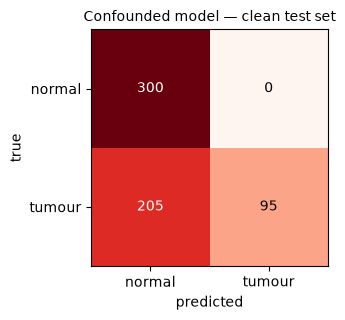

In [14]:
# D2 — reliance test: recall of the artifact class WITH vs WITHOUT the artifact (both models)
art_idx = np.where(yte_s == ARTIFACT_LABEL)[0]
def class_recall(net, with_art):
    p = predict(net, xte_s[art_idx], transform=add_artifact if with_art else None)
    return (p == ARTIFACT_LABEL).mean()

rec = {(m, w): class_recall(net, w) for m, net in [("confounded", model_cf), ("clean", model_clean)]
       for w in (True, False)}
lab = class_names[ARTIFACT_LABEL]
print(f"{lab} recall            WITH artifact | WITHOUT artifact")
print(f"confounded model : {rec[('confounded', True)]:.3f}         | {rec[('confounded', False)]:.3f}")
print(f"clean control    : {rec[('clean', True)]:.3f}         | {rec[('clean', False)]:.3f}")

# overall clean-test performance of the confounded model (the 'real world' with no artifact)
pred_cf_clean = predict(model_cf, xte_s)
test_acc_cf_clean = (pred_cf_clean == yte_s).mean()
print(f"\nconfounded model, accuracy on the CLEAN test set: {test_acc_cf_clean:.3f}  (clean model: {test_acc_clean:.3f})")
plot_cm(yte_s, pred_cf_clean, "Confounded model — clean test set", "D2_confusion_confounded_clean.png");

In [15]:
# D3 + D4 — flip rate on the OTHER class, with the clean model as control
oth_idx = np.where(yte_s == OTHER_LABEL)[0]
def flip_rate(net):
    p = predict(net, xte_s[oth_idx], transform=add_artifact)
    return (p == ARTIFACT_LABEL).mean()
def base_rate(net):   # how often it calls them ARTIFACT_LABEL with NO artifact (the baseline error)
    return (predict(net, xte_s[oth_idx]) == ARTIFACT_LABEL).mean()

flip_cf, flip_clean = flip_rate(model_cf), flip_rate(model_clean)
base_cf, base_clean = base_rate(model_cf), base_rate(model_clean)
print(f"{len(oth_idx)} {class_names[OTHER_LABEL]} test tiles; artifact added; % called {class_names[ARTIFACT_LABEL]}:")
print(f"  confounded model : {flip_cf:.1%}   (without artifact: {base_cf:.1%})")
print(f"  clean control    : {flip_clean:.1%}   (without artifact: {base_clean:.1%})")
print(f"  gap (confounded − clean) = {flip_cf - flip_clean:+.1%}")

300 normal test tiles; artifact added; % called tumour:
  confounded model : 97.0%   (without artifact: 0.0%)
  clean control    : 12.0%   (without artifact: 3.3%)
  gap (confounded − clean) = +85.0%


In [16]:
# Summary table — saved for the report
summary = pd.DataFrame([
    ("artifact", ARTIFACT), ("artifact injected into", class_names[ARTIFACT_LABEL]),
    ("artifact area (% of tile)", f"{ART_MASK.float().mean():.1%}"),
    ("clean model — val accuracy", f"{val_acc_clean:.3f}"),
    ("clean model — test accuracy", f"{test_acc_clean:.3f}"),
    ("clean model — test acc, stain shift", f"{rob['stain shift']:.3f}"),
    ("clean model — test acc, darker scan", f"{rob['darker scan']:.3f}"),
    ("confounded model — val accuracy (poisoned val)", f"{val_acc_cf:.3f}"),
    ("confounded model — clean test accuracy", f"{test_acc_cf_clean:.3f}"),
    (f"confounded — {lab} recall WITH artifact", f"{rec[('confounded', True)]:.3f}"),
    (f"confounded — {lab} recall WITHOUT artifact", f"{rec[('confounded', False)]:.3f}"),
    (f"clean — {lab} recall WITH artifact", f"{rec[('clean', True)]:.3f}"),
    (f"clean — {lab} recall WITHOUT artifact", f"{rec[('clean', False)]:.3f}"),
    ("flip rate — confounded", f"{flip_cf:.1%}"), ("flip rate — clean control", f"{flip_clean:.1%}"),
] + [(f"{n} — mean Grad-CAM share on artifact", f"{gm:.0%}") for n, gm, _, _, _ in rows]
  + [(f"{n} — mean occlusion share on artifact", f"{om:.0%}") for n, _, _, om, _ in rows],
  columns=["metric", "value"])
summary.to_csv("module10_results.csv", index=False)
print(summary.to_string(index=False))
print("\nsaved -> module10_results.csv and figures/*.png")

                                        metric       value
                                      artifact scanner_tag
                        artifact injected into      tumour
                     artifact area (% of tile)        4.3%
                    clean model — val accuracy       0.965
                   clean model — test accuracy       0.955
           clean model — test acc, stain shift       0.942
           clean model — test acc, darker scan       0.947
confounded model — val accuracy (poisoned val)       1.000
        confounded model — clean test accuracy       0.658
      confounded — tumour recall WITH artifact       1.000
   confounded — tumour recall WITHOUT artifact       0.317
           clean — tumour recall WITH artifact       0.980
        clean — tumour recall WITHOUT artifact       0.943
                        flip rate — confounded       97.0%
                     flip rate — clean control       12.0%
  confounded — mean Grad-CAM share on artifact         1

### Part D — interpretation notes

Although the confounded model reached 1.000 validation accuracy by epoch 2, the Part D battery shows that the synthetic scanner tag drives its predictions rather than tissue histology:   

Attribution localization (D1_maps_example.png): The confounded model placed 13% of its Grad-CAM mass (~3× the 4.3% tag area, limited by the coarse 4 × 4 map) and 69% of its occlusion probability drop on the tag, versus 1% and 11% for the clean control. (Note: The clean control's occlusion map looks colorful only because each panel is auto-scaled to its own maximum; its actual probability drops are tiny, as in Part B.)   

Tag-removal collapse (D2_confusion_confounded_clean.png): Removing the tag caused confounded tumour recall to fall from 1.000 to 0.317 (missing 205/300 clean tumours) and clean test accuracy to drop to 0.658, whereas the clean control maintained 0.943 tumour recall and 0.955 accuracy.   

Control gap: Adding the tag to healthy normal test tiles flipped 97.0% of normal tiles to "tumour" predictions in the confounded model (0.0% without), compared to a modest out-of-distribution rise from 3.3% to 12.0% in the clean control. This 85.0-percentage-point control gap shows that the confounded model explicitly learned the tag as a shortcut.   

Final Verdict: Reject the confounded model. Its 1.000 validation score was an artifact of a poisoned validation split sharing the same site-specific tag. 

---
# Part E — Report
Written separately as a 3–4 page PDF in this folder (`Module10_Report.pdf`).

`Kernel → Restart & Run All` before committing.